Dataset loaded and target column prepared
   age     sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  \
0   63    male   1       145   233    1        2      150      0      2.3   
1   67    male   4       160   286    0        2      108      1      1.5   
2   67    male   4       120   229    0        2      129      1      2.6   
3   37    male   3       130   250    0        0      187      0      3.5   
4   41  female   2       130   204    0        2      172      0      1.4   

   slope   ca  thal  target  
0      3  0.0   6.0       0  
1      2  3.0   3.0       1  
2      2  2.0   7.0       1  
3      3  0.0   3.0       0  
4      1  0.0   3.0       0  

Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 297 entries, 0 to 296
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       297 non-null    int64  
 1   sex       297 non-null    str    
 2   cp        297 non-null    int64  
 3   trestb

C:\Users\suren\AppData\Local\Temp\ipykernel_11048\3803594240.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="target", data=df, palette="Set2")


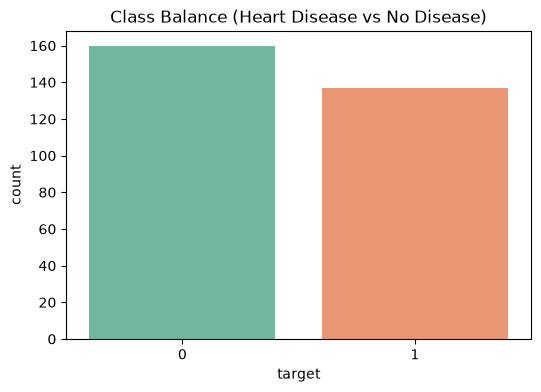

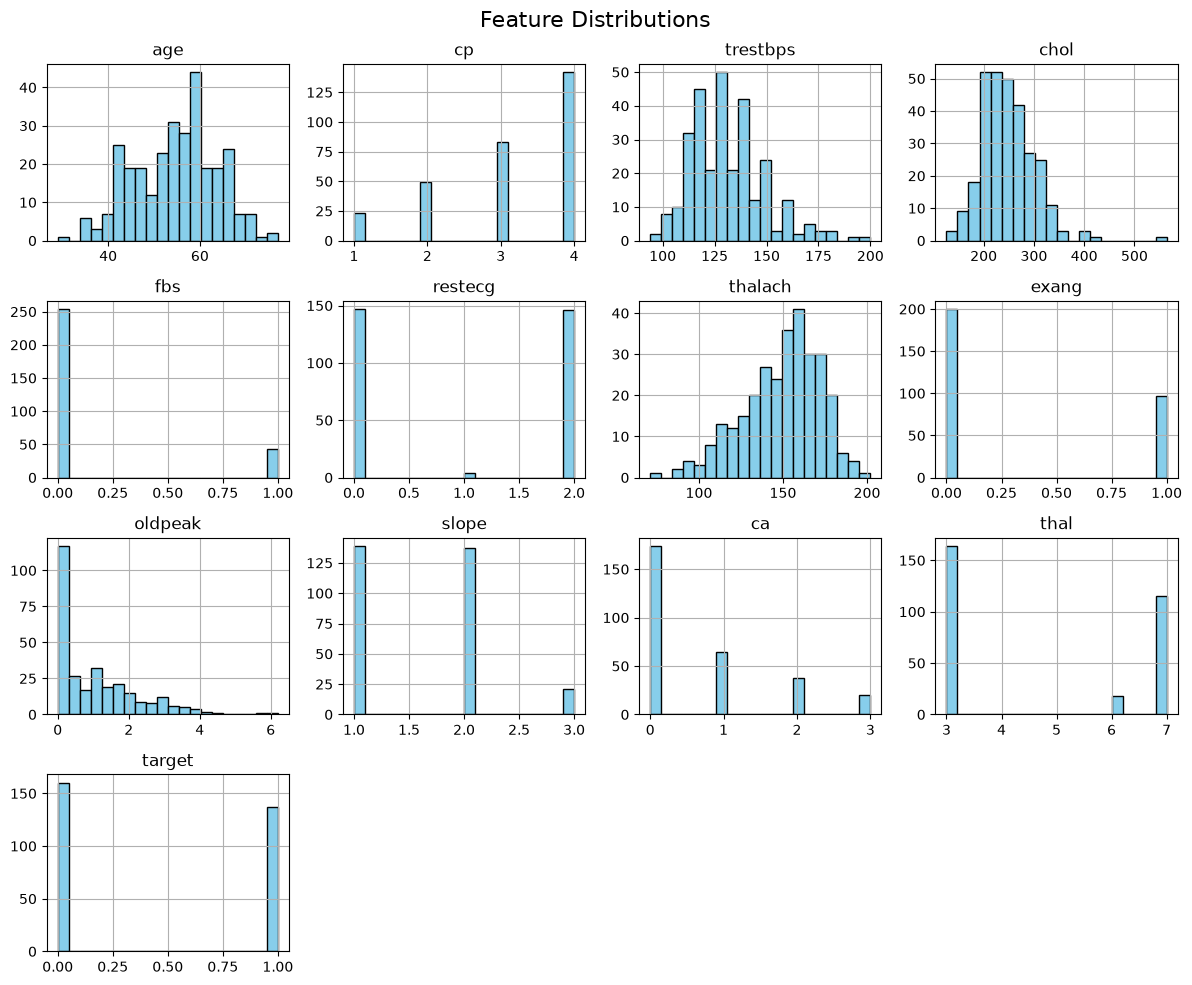

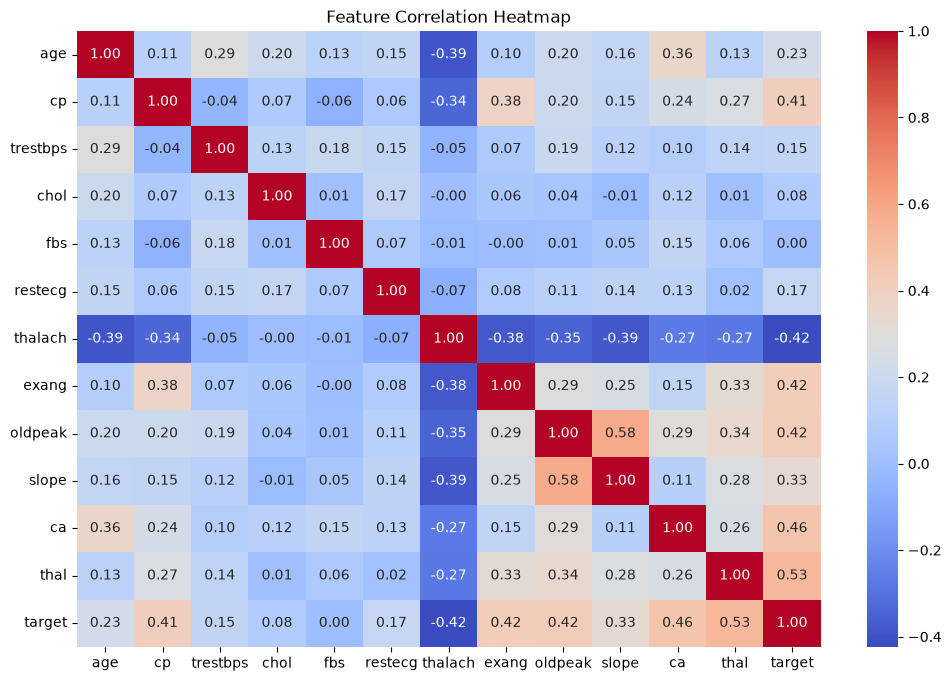

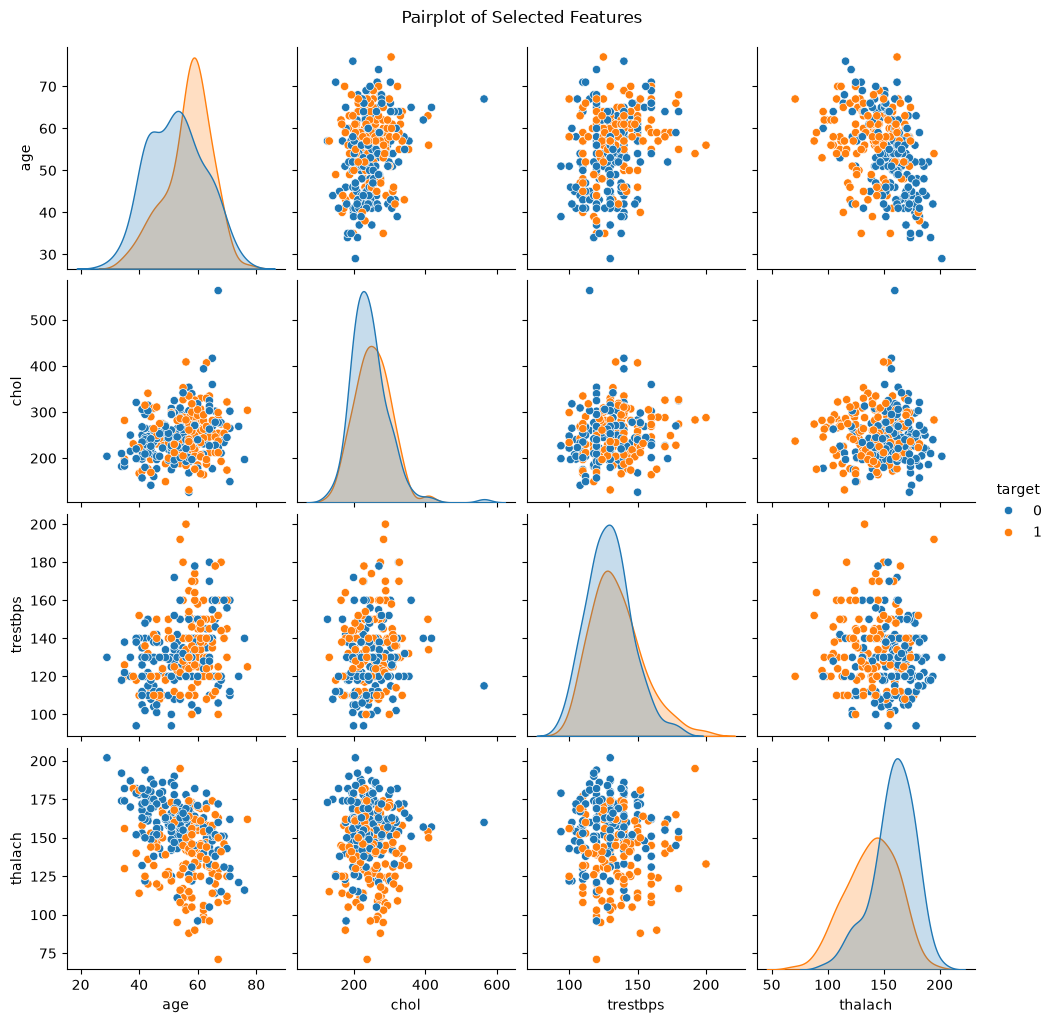

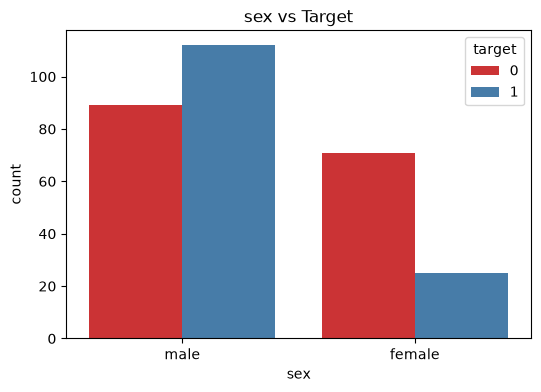

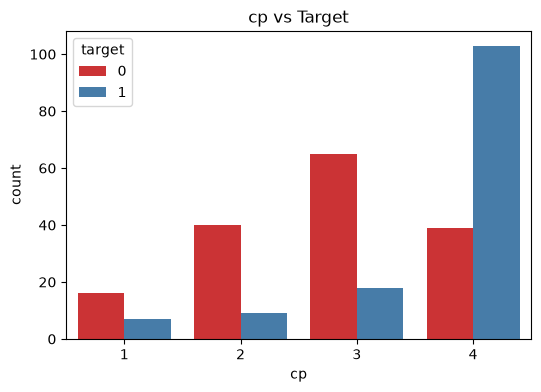

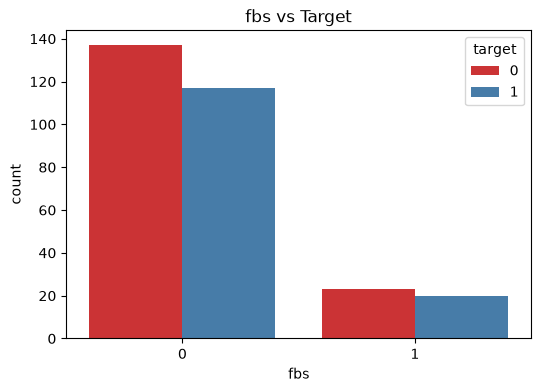

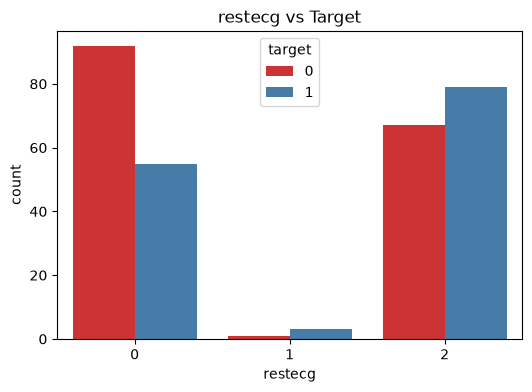

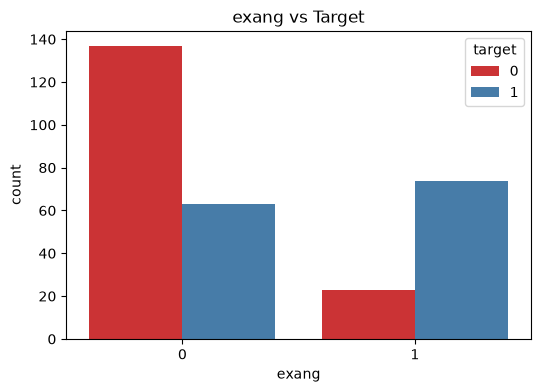

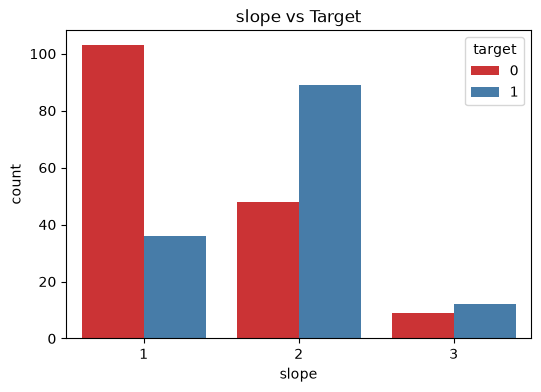

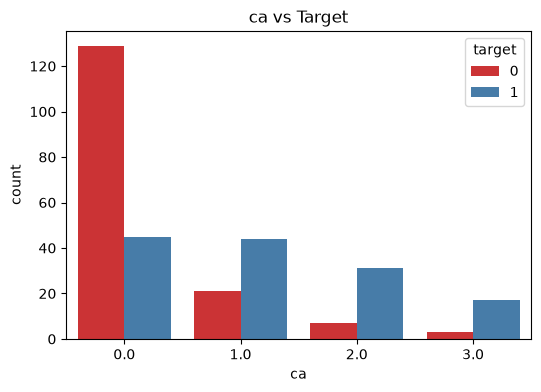

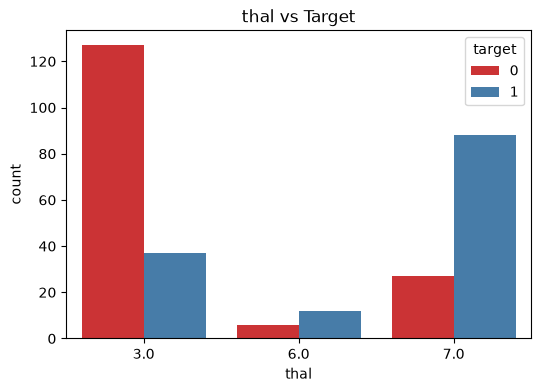

In [4]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv("../data/processed/heart_disease_clean.csv")

# Convert target column (num) into binary: 0 = no disease, 1 = disease
df["target"] = df["num"].apply(lambda x: 1 if x > 0 else 0)
df.drop(columns=["num"], inplace=True)

print("Dataset loaded and target column prepared")
print(df.head())

# -------------------------------
# 1. Dataset Overview
# -------------------------------
print("\nDataset Info:")
print(df.info())
print("\nSummary Statistics:")
print(df.describe())

# -------------------------------
# 2. Class Balance
# -------------------------------
plt.figure(figsize=(6,4))
sns.countplot(x="target", data=df, palette="Set2")
plt.title("Class Balance (Heart Disease vs No Disease)")
plt.show()

# -------------------------------
# 3. Histograms for Numeric Features
# -------------------------------
df.hist(figsize=(12,10), bins=20, color="skyblue", edgecolor="black")
plt.suptitle("Feature Distributions", fontsize=16)
plt.tight_layout()
plt.show()

# -------------------------------
# 4. Correlation Heatmap
# -------------------------------
plt.figure(figsize=(12,8))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Feature Correlation Heatmap")
plt.show()

# -------------------------------
# 5. Pairplot 
# -------------------------------
sns.pairplot(df[["age","chol","trestbps","thalach","target"]], hue="target", diag_kind="kde")
plt.suptitle("Pairplot of Selected Features", y=1.02)
plt.show()

# -------------------------------
# 6. Categorical Feature Analysis
# -------------------------------
categorical_cols = ["sex","cp","fbs","restecg","exang","slope","ca","thal"]

for col in categorical_cols:
    plt.figure(figsize=(6,4))
    sns.countplot(x=col, hue="target", data=df, palette="Set1")
    plt.title(f"{col} vs Target")
    plt.show()